# Google Quick, Draw! - First CNN
**Task:** classify a 28×28×1 greyscale sketch into one of 8 classes (multiclass classification).
**Input:** `../data/quickdraw/quickdraw_8class_processed.npz`, created by `03_QuickDraw_Classical_MLP_Reviewed.ipynb`.

**Evaluation protocol:** train on the training set, monitor and evaluate on the **validation** set only.
The **test set is not used in this notebook**. It is evaluated once, in the final test notebook, with the final model.


## 1. Setup

In [1]:
from pathlib import Path
import time

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Reproducibility: seeds Python, NumPy and TensorFlow in one call.
# (Tiny run-to-run differences can still happen on GPU because of non-deterministic kernels.)
SEED = 42
keras.utils.set_random_seed(SEED)

# Relative paths: same layout as the EDA notebook
data_path = Path("../data/quickdraw/quickdraw_8class_processed.npz")
figures_dir = Path("../figures")
results_dir = Path("../results")
figures_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
GPU available: False


## 2. Load the processed data

In [2]:
data = np.load(data_path)

X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
# X_test / y_test are deliberately NOT loaded here: the test set is only used once, in the final test notebook
categories = data["categories"].tolist()
n_classes = len(categories)

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Classes:", categories)
print("Pixel range:", X_train.min(), "to", X_train.max())

Train: (19200, 28, 28, 1) (19200,)
Val:   (2400, 28, 28, 1) (2400,)
Classes: ['airplane', 'apple', 'bicycle', 'cat', 'fish', 'guitar', 'house', 'tree']
Pixel range: 0.0 to 1.0


## 3. CNN Architecture

The initial CNN consists of two convolutional blocks followed by a small classifier.

Layers to convert 2D into 3D. The first layer has 32 filters of 3x3 pixels each. Each filter sweeps over the entire image, examining one small patch at a time, and detects a simple local pattern – a short edge, a curve or a corner where two strokes meet. We pad with “same” so that the output is still 28x28. In the second block with 64 filters, the output of the first block is used instead of raw pixels. It can group them into more complicated shapes such as a circle which can be a wheel, two lines intersecting at a point which can be a roof, or a long shape with an object crossing it which can be a wing. Both convolutional layers use ReLU activation that allows the network to learn non-linear patterns by setting negative values to zero.

**MaxPooling2D layers** - Each conv layer is followed by a 2x2 max pooling layer that takes only the largest value in each 2x2 area. This halves the width and height of the image (28x28 to 14x14, and then 14x14 to 7x7). This reduces the computational load for the following layers. This also means that the output is minimally affected if a stroke moves a pixel or two. This is good, because people never draw things at exactly the same place.

**Dense Layer and Flatten Layer* - After the second block, the number of values is 3,136 (7x7x64). This is flattened out into a single long list and fed into a dense layer of 128 units. This layer takes all the features found by the convolution layers and combines them to decide what the drawing is.

**Withdrawal** - The dropout layer at each training step randomly disables 30% of the units in the dense layer. To reduce overfitting, the network cannot rely too heavily on any single unit, and thus must learn more general patterns. Dropout is only used during training , and is turned off when the model is making predictions .

**output of softmax** - The last layer has 8 units , one for each class . Softmax is used to convert the outputs to 8 probabilities adding up to 1. The predicted class is the class with the highest probability. We train with Adam optimiser (learning rate 0.001) and sparse categorical cross-entropy loss function, as our labels are encoded as integers from 0 to 7.

**Why the model is small** - The dense layer has about 400,000 of a model's 421,384 parameters after flattening. The architecture was deliberately kept compact. The images are simply 28x28 greyscale sketches composed of simple strokes. So a network that is not too deep is not needed to recognise the important shapes. We also have only 19,200 training images and a significantly larger model would be more prone to overfitting and memorisation. A small model can be trained on a laptop in less than a minute, so many settings can be tried.

**Why CNNs are superior to flattening models** - The classical and MLP models treat each pixel position as a separate feature and lose track of which pixels are neighbouring. So each image is treated as a flat list of 784 pixels. This assumption is called spatial inductive bias . A CNN is built on this assumption . It preserves the 2D layout of the image . The same filter is used at all locations in the image, so a curve or corner detected at one location can be detected at another location. The weights are shared as well. This makes the CNN much better at handling drawings that are slightly modified or translated . It also requires less parameters to learn useful features .

In [3]:
def build_cnn(filters=(32, 64), dense_units=128, dropout=0.3, learning_rate=1e-3):
    """Small baseline CNN. Arguments are exposed so tuning can vary them."""
    model = keras.Sequential([
        keras.Input(shape=(28, 28, 1)),

        # Block 1: 32 filters of 3x3 -> local edges/strokes; 'same' padding keeps 28x28
        layers.Conv2D(filters[0], (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),                       # 28x28 -> 14x14

        # Block 2: 64 filters -> combinations of strokes (shapes/parts)
        layers.Conv2D(filters[1], (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),                       # 14x14 -> 7x7

        # Classifier head
        layers.Flatten(),                                  # 7*7*64 = 3136 features
        layers.Dense(dense_units, activation="relu"),
        layers.Dropout(dropout),                           # regularisation
        layers.Dense(n_classes, activation="softmax"),     # one probability per class
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        # labels are integers 0-7, so use the *sparse* version of categorical cross-entropy
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

cnn = build_cnn()
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,384 (1.61 MB)

 Trainable params: 421,384 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Training with validation monitoring
- **Validation data:** after every epoch, loss and accuracy are measured on the 2,400 validation images, which are never trained on.
- **Early stopping:** if validation loss doesn't improve for 3 epochs in a row, training stops and the weights from the best epoch are restored. This stops the model from continuing to overfit.
- **Batch size 64 / max 30 epochs:** standard starting values. Early stopping usually ends training before 30.

In [4]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)

start = time.perf_counter()
history = cnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop],
    verbose=2,
)
train_time = time.perf_counter() - start

best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nTraining time: {train_time:.1f} s | epochs run: {len(history.history['loss'])} | best epoch: {best_epoch}")

Epoch 1/30
300/300 - 4s - 14ms/step - accuracy: 0.8330 - loss: 0.5241 - val_accuracy: 0.9171 - val_loss: 0.2758
Epoch 2/30
300/300 - 3s - 10ms/step - accuracy: 0.9224 - loss: 0.2593 - val_accuracy: 0.9383 - val_loss: 0.2125
Epoch 3/30
300/300 - 5s - 18ms/step - accuracy: 0.9379 - loss: 0.2067 - val_accuracy: 0.9396 - val_loss: 0.1959
Epoch 4/30
300/300 - 3s - 10ms/step - accuracy: 0.9478 - loss: 0.1700 - val_accuracy: 0.9396 - val_loss: 0.1814
Epoch 5/30
300/300 - 3s - 11ms/step - accuracy: 0.9539 - loss: 0.1437 - val_accuracy: 0.9479 - val_loss: 0.1743
Epoch 6/30
300/300 - 4s - 13ms/step - accuracy: 0.9631 - loss: 0.1158 - val_accuracy: 0.9467 - val_loss: 0.1759
Epoch 7/30
300/300 - 3s - 12ms/step - accuracy: 0.9689 - loss: 0.0953 - val_accuracy: 0.9500 - val_loss: 0.1832
Epoch 8/30
300/300 - 3s - 10ms/step - accuracy: 0.9735 - loss: 0.0815 - val_accuracy: 0.9454 - val_loss: 0.1904

Training time: 29.4 s | epochs run: 8 | best epoch: 5


## 5. Training and validation curves

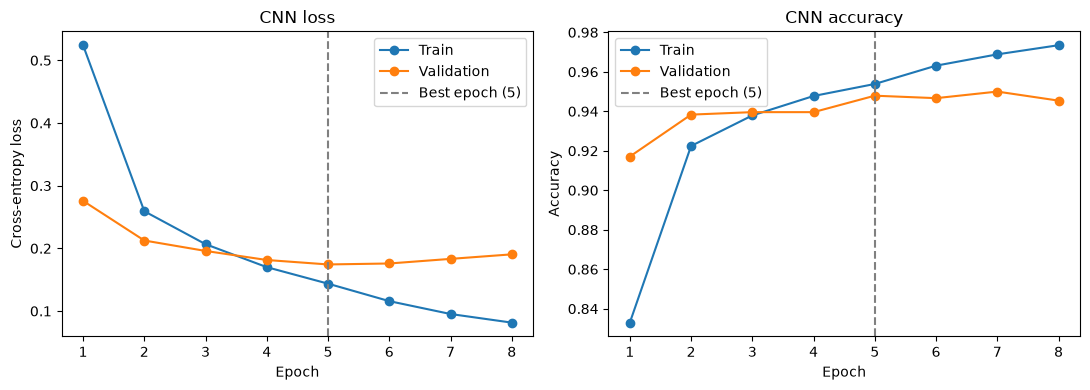

In [5]:
hist = history.history
epochs = range(1, len(hist["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epochs, hist["loss"], marker="o", label="Train")
axes[0].plot(epochs, hist["val_loss"], marker="o", label="Validation")
axes[0].axvline(best_epoch, color="grey", linestyle="--", label=f"Best epoch ({best_epoch})")
axes[0].set_title("CNN loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(epochs, hist["accuracy"], marker="o", label="Train")
axes[1].plot(epochs, hist["val_accuracy"], marker="o", label="Validation")
axes[1].axvline(best_epoch, color="grey", linestyle="--", label=f"Best epoch ({best_epoch})")
axes[1].set_title("CNN accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_cnn_v1_curves.png", dpi=150, bbox_inches="tight")
plt.show()

We can see from the curves that the model learns fast and starts to overfit a bit after epoch 5. Epoch 1/8 0.52 Epoch 2/8 0.32 Epoch 3/8 0.22 Epoch 4/8 0.17 Epoch 5/8 0.14 Epoch 6/8 0.11 Epoch 7/8 0.09 Epoch 8/8 0.08 The training loss is decreasing with each epoch. The validation loss decreases rapidly initially, hitting its minimum near epoch 5 (~0.17), and then begins to increase again to about 0.19 by epoch 8. This is the classic sign of overfitting: after epoch 5, the model keeps improving on the training data but it degrades on new data. This is because the model is starting to memorise the training drawings instead of learning general patterns. The same phenomenon is observed for the accuracy curves. The training accuracy continues to increase until it is about 0.97. The validation accuracy plateaus between about 0.94 and 0.95 starting at epoch 3 and does not improve much after that.

That’s why we’ve introduced early stopping. It monitors the validation loss and stops training if the loss does not improve for 3 consecutive epochs (patience = 3). The training process was stopped in epoch 8 as the most successful validation loss occurred in epoch 5. We set restore_best_weights=True so the final model has the weights from epoch 5 rather than the slightly overfitted weights from epoch 8. The training accuracy at the best epoch was 0.9539 and the validation accuracy was 0.9479, a difference of just around 0.6 percentage points. This means that the model we kept is not significantly over-fitted. The gap only really opens up after epoch 5, up to about 2.8 points by epoch 8 (about 0.974 vs 0.946).

One odd thing that may appear odd is that the validation accuracy is higher than the training accuracy for the first two epochs and the validation loss is lower than the training loss. There are two reasons for this. At first, Keras shows the training numbers averaged over the whole epoch while the model is still improving. But the validation numbers are taken at the end of the epoch. Second, the model is effectively weaker when it is evaluated on the training data. Dropout is enabled during training but disabled during validation.

## 6. Validation evaluation (preliminary)
Accuracy alone isn't enough, so this reports **macro precision, recall and F1** too: each class's score is computed separately and the 8 are averaged, so every class counts equally. The confusion matrix shows *which* classes get mixed up.
These are **validation** results for the first model, not final test results.

In [6]:
val_probs = cnn.predict(X_val, verbose=0)
val_pred = val_probs.argmax(axis=1)          # most probable class for each image

val_acc = accuracy_score(y_val, val_pred)
print(f"Validation accuracy: {val_acc:.4f}\n")
print(classification_report(y_val, val_pred, target_names=categories, digits=4))

Validation accuracy: 0.9479

              precision    recall  f1-score   support

    airplane     0.9116    0.8933    0.9024       300
       apple     0.9697    0.9600    0.9648       300
     bicycle     0.9513    0.9767    0.9638       300
         cat     0.9048    0.8867    0.8956       300
        fish     0.9123    0.9367    0.9243       300
      guitar     0.9542    0.9733    0.9637       300
       house     0.9932    0.9800    0.9866       300
        tree     0.9865    0.9767    0.9816       300

    accuracy                         0.9479      2400
   macro avg     0.9480    0.9479    0.9479      2400
weighted avg     0.9480    0.9479    0.9479      2400



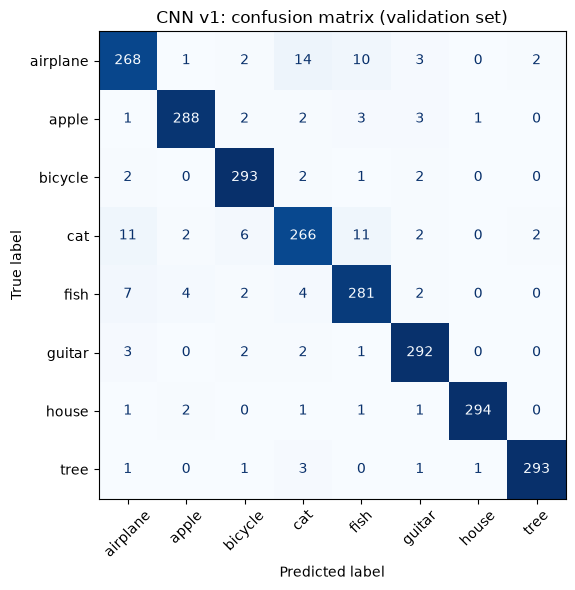

Most common confusions (true -> predicted : count):
  airplane  -> cat       : 14
  cat       -> fish      : 11
  cat       -> airplane  : 11
  airplane  -> fish      : 10
  fish      -> airplane  : 7


In [7]:
cm = confusion_matrix(y_val, val_pred)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=categories).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title("CNN v1: confusion matrix (validation set)")
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_cnn_v1_confusion_val.png", dpi=150, bbox_inches="tight")
plt.show()

# The 5 most frequent confusions (off-diagonal cells), to discuss in the error analysis
off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
top = np.dstack(np.unravel_index(np.argsort(off_diag.ravel())[::-1][:5], cm.shape))[0]
print("Most common confusions (true -> predicted : count):")
for t, p in top:
    print(f"  {categories[t]:9s} -> {categories[p]:9s} : {off_diag[t, p]}")

If we look at the confusion matrix, it seems that our first CNN makes most of the mistakes to differentiate between airplane, cat and fish. The most confused classes are the aircraft and cat, which account for a total of 25 errors. The airplane is confused with a cat 14 times, and the cat is confused with an airplane 11 times. The next pair of errors is airplane and fish, with 17 (10 in one direction and 7 in the other). Cat and fish have 15 (cat predicted as fish 11 times and fish as cat 4 times). Nearly half of the 125 errors on the validation set are due to confusion between these three classes, 57 errors. The cat is the worst class, with 266 out of 300, and the airplane is not much better with 268. The cat is also predicted as a bicycle many times (6), maybe due to its round head and eyes looking like wheels. The other classes are much better, the house got 294 correct, the bicycle and tree got 293, and the guitar got 292.

We think that there are a few reasons for this. airplanes, cats and fish are often drawn in a similar way. They have one main body, and a few small pointy bits sticking out. For example, a plane might have wings and a tail, a cat might have ears and a tail, a fish might have fins and a tail. The drawings can look very similar, as these bits are only a few pixels in size on a 28x28 image. Furthermore, players are given 20 seconds to make their drawings, so most of them are extremely simple and can be drawn in just a few strokes. The plane is represented by a line with a cross on it and the fish by an oval with a triangle at the end. This means that the model has very little information to work with. In addition, individuals portray these classes in various ways. airplanes can be turned in any direction . Some cats are just a face, some have a whole body, legs and a tail. This makes it difficult for the model to learn a unique pattern for each class. It’s the classes where it shines, like guitar, house, and tree, that everyone tends to represent the same way. For instance, a house is almost always a square with a triangle on top, so it becomes much easier to recognise.

## 7. Misclassified examples (validation)

Misclassified: 125 of 2400 validation images


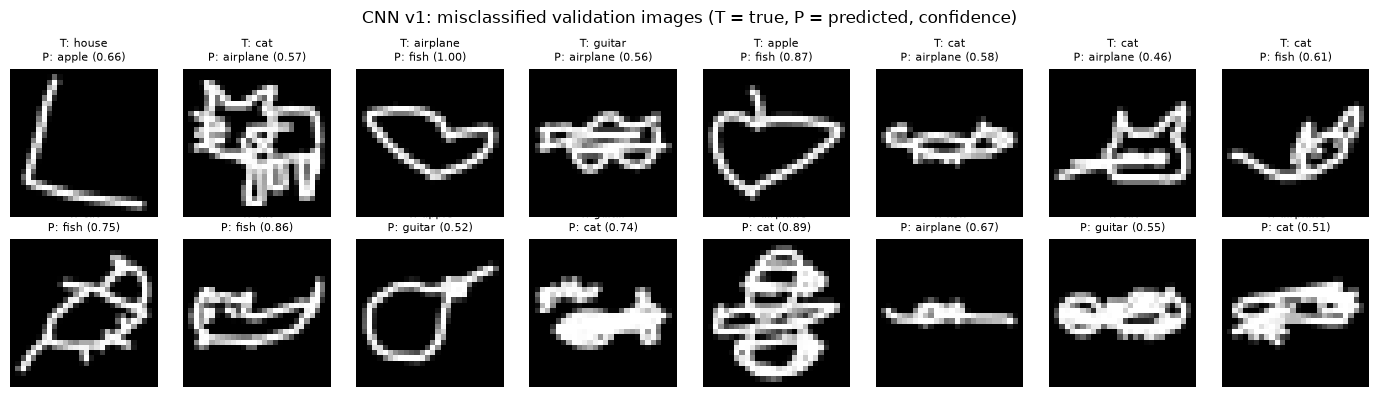

In [8]:
wrong = np.where(val_pred != y_val)[0]
print(f"Misclassified: {len(wrong)} of {len(y_val)} validation images")

rng = np.random.default_rng(SEED)
show = rng.choice(wrong, size=min(16, len(wrong)), replace=False)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(X_val[i].squeeze(), cmap="gray")
    ax.set_title(f"T: {categories[y_val[i]]}\nP: {categories[val_pred[i]]} ({val_probs[i].max():.2f})", fontsize=8)
    ax.axis("off")
for ax in axes.ravel()[len(show):]:
    ax.axis("off")
fig.suptitle("CNN v1: misclassified validation images (T = true, P = predicted, confidence)")
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_cnn_v1_misclassified_val.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Record the result

In [9]:
from sklearn.metrics import precision_recall_fscore_support

p, r, f1, _ = precision_recall_fscore_support(y_val, val_pred, average="macro")
summary = {
    "model": "CNN v1 (2 conv blocks 32/64, dense 128, dropout 0.3, Adam lr=1e-3, batch 64)",
    "params": cnn.count_params(),
    "epochs_run": len(hist["loss"]),
    "best_epoch": best_epoch,
    "train_time_s": round(train_time, 1),
    "val_accuracy": round(val_acc, 4),
    "val_macro_precision": round(p, 4),
    "val_macro_recall": round(r, 4),
    "val_macro_f1": round(f1, 4),
}
for k, v in summary.items():
    print(f"{k:20s}: {v}")

# Save so the result can be compared with the baselines and the tuning runs
import json
with open(results_dir / "quickdraw_cnn_v1_val.json", "w") as f:
    json.dump(summary, f, indent=2)

model               : CNN v1 (2 conv blocks 32/64, dense 128, dropout 0.3, Adam lr=1e-3, batch 64)
params              : 421384
epochs_run          : 8
best_epoch          : 5
train_time_s        : 29.4
val_accuracy        : 0.9479
val_macro_precision : 0.948
val_macro_recall    : 0.9479
val_macro_f1        : 0.9479


## 9. Findings so far and next steps
Our first CNN achieved a validation accuracy of 0.9479, macro F1 of 0.9479, macro precision of 0.948 and macro recall of 0.9479. This means that 2,275 of the 2,400 validation drawings were correctly classified. The model is not biased to any specific class, since precision and recall are almost same. airplane, cat and fish accounted for the majority of the 125 errors. The airplane and cat were most confused (25 errors) followed by airplane and fish (17) and cat and fish (15). This makes up almost half the errors. The cat was the most vulnerable class (266/300) with the airplane not far behind (268/300). Bicycle, tree and guitar were all correctly identified in the house, with a least 292 out of 300 correct responses. This is because we feel that airplanes, cats and fish are often portrayed as a body with a few pointed bits and so can look quite similar in quick simple drawings at 28x28.

There is some overfitting visible in the curves but this is only visible after epoch 5. The training loss was decreasing consistently over the period. The validation loss was lowest at epoch 5 and then gradually started to increase. The training accuracy continued to increase while the validation accuracy was stable around 0.95. We saved the model before it started to overfit, stopping training at epoch 8 with a patience of 3 and restoring the weights from epoch 5. The training accuracy was 0.9539 and the validation accuracy was 0.9479, a difference of only 0.6 percentage points at that time. Overall this first model is already a good base. The main improvements to aim for are the airplane, cat and fish confusions.

**Plan:** compare against the baselines and the MLP on the same validation split; tune a few justified hyperparameters (filters, dropout, learning rate, batch size) using **validation only**; keep the best configuration for the single final test evaluation.